In [1]:
import chipwhisperer as cw
import numpy as np
import struct
import matplotlib.pyplot as plt
import time
scope = cw.scope()
target = cw.target(scope)
scope.default_setup()

(ChipWhisperer Other WARNING|File __init__.py:69) ChipWhisperer update available! See https://chipwhisperer.readthedocs.io/en/latest/installing.html for updating instructions


make: Entering directory '/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/8-bit/firmware/timing_attack'
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
.
Welcome to another exciting ChipWhisperer target build!!
avr-gcc (GCC) 14.2.0
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWLITEXMEGA 
.
Compiling:
-en     timing_attack.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/XMEGA_AES_driver.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/uart.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/usart_driver.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/xmega_hal.c ...
-e Done!
.
LINKING:
-en     timing_attack-CWLITEXMEGA.elf ...
Memory region         Used Size  Region Size  %age Used
  

ReLU capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for ReLU! Plotting results...


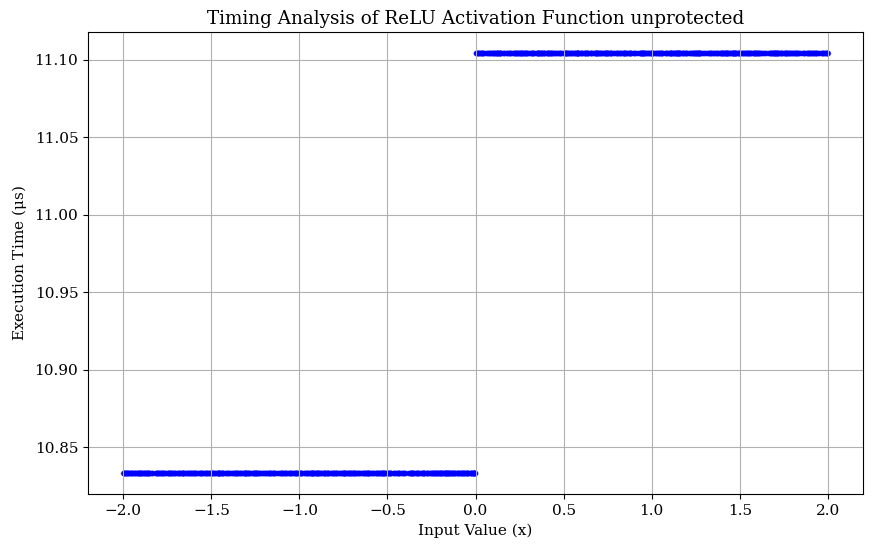

Capturing sigmoid unprotected...


sigmoid capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for sigmoid! Plotting results...


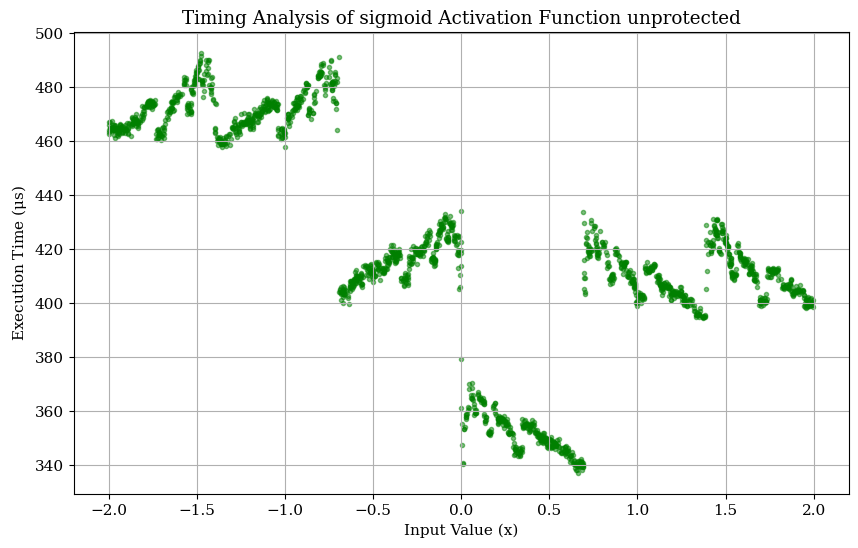

Capturing tanh unprotected...


tanh capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for tanh! Plotting results...


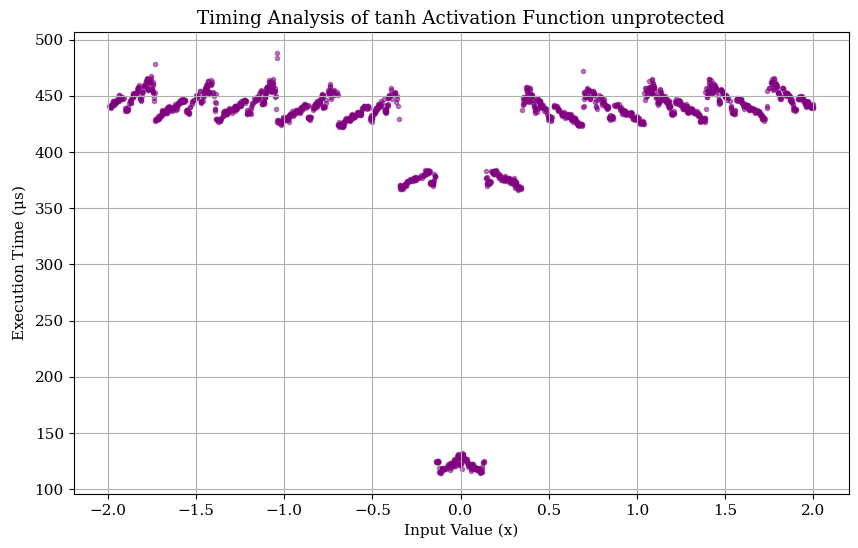

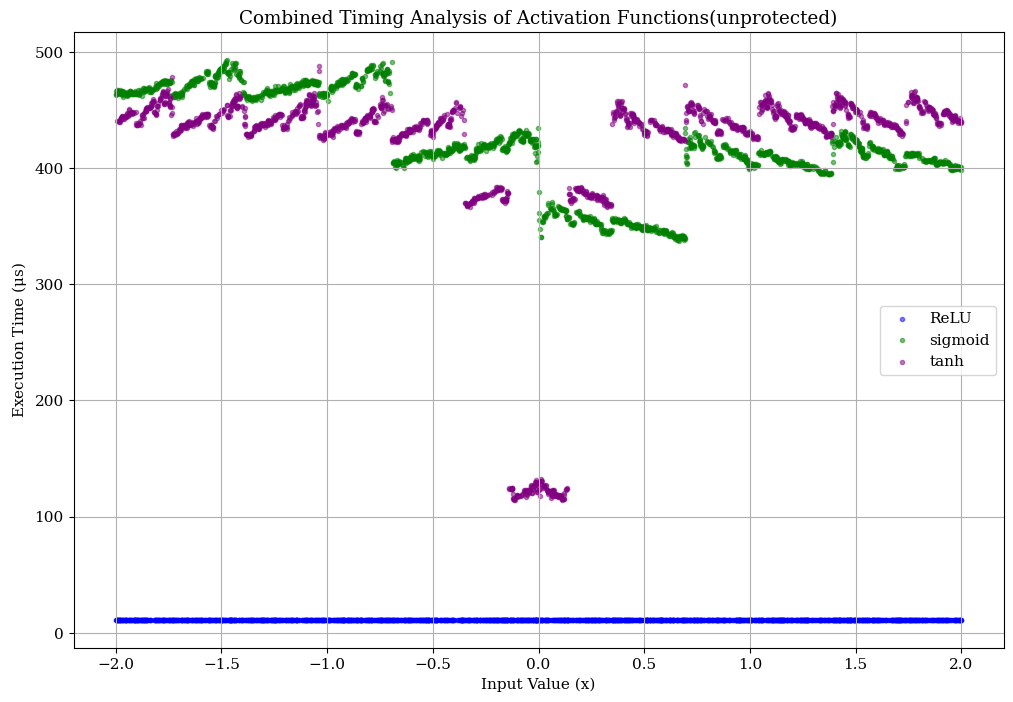


--- Execution Time Statistics (Microseconds) ---
Function   | Fastest (C) | Slowest (C) | Average   
-----------------------------------------------
ReLU       | 10.83      | 11.10      | 10.97     
sigmoid    | 351.64     | 471.67     | 421.13    
tanh       | 121.79     | 442.11     | 413.34    
-----------------------------------------------


--- Countermeasure Parameters ---
Cluster Fastest: 10.83 us
Cluster Slowest: 471.67 us
Absolute Fastest: 10.83 us
Absolute Slowest: 492.65 us
Absolute Delta t/Mean (mu): 460.84 us
Max Local Difference/StdDev (sigma): 373.61 us
------------------------------------------


In [4]:
"""
Timing Attack Analysis Script for 8-bit AVR

This script utilizes the ChipWhisperer toolchain to perform a side-channel 
timing analysis on unprotected neural network activation functions (ReLU, Sigmoid, Tanh).
It compiles the firmware, flashes it to the target board, feeds it random floating-point inputs, 
and measures the exact execution time (in clock cycles/microseconds) using the oscilloscope's trigger. 

The resulting timing leaks are plotted 
and analyzed using K-Means clustering to determine the parameters needed for a 
randomized delay countermeasure.


"""

import struct
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans
from tqdm.notebook import tqdm
import os


plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})
# --- Target Setup & Firmware Compilation ---

PLATFORM = 'CWLITEXMEGA'
FW_PATH = "../firmware/timing_attack/"
!make -C "{FW_PATH}" PLATFORM={PLATFORM} CRYPTO_TARGET=NONE
hex_path = os.path.join(FW_PATH, f"timing_attack-{PLATFORM}.hex")
cw.program_target(scope, cw.programmers.XMEGAProgrammer, hex_path)

def capture_and_plot(activation_name, choice_val=None, num_traces=2000, suffix="", color="red"):

    # Generate 2000 random inputs
    inputs = np.random.uniform(-2, 2, num_traces)

    # Store execution times in microseconds
    execution_times_us = [] 

    print(f"Capturing {activation_name}{suffix}...")

    # used to convert cycles to time
    adc_freq = scope.clock.adc_freq 

    for x in tqdm(inputs, desc=f"{activation_name} capture"):

        # pack our chosen activation function and input value
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', x))
        
        scope.arm()

        # send the input to the target, this starts the execution
        target.simpleserial_write('p', pt)
        
        # wait for the execution to finish
        ret = scope.capture()
        if ret:
            print("Timeout error! The trigger never fired or finished.")
            break
            
        # Get the number of cycles from the ADC
        cycles = scope.adc.trig_count

        # Convert cycles to actual time in microseconds (1e6 microseconds in a second)
        time_us = (cycles / adc_freq) * 1e6 

        # append the execution time to the list
        execution_times_us.append(time_us)
        
        # read the output from the target(acknowledge)
        target.simpleserial_read('r', 4)

    print(f"Capture complete for {activation_name}! Plotting results...")

    plt.figure(figsize=(10, 6))
    plt.scatter(inputs, execution_times_us, marker='.', color=color, alpha=0.5)
    plt.title(f"Timing Analysis of {activation_name} Activation Function{suffix}")
    plt.xlabel("Input Value (x)")
    plt.ylabel(r"Execution Time ($\mu s$)")
    plt.grid(True)
    plt.savefig(f"{activation_name}-{suffix}.pdf", bbox_inches='tight')
    plt.show()
   
    
    return inputs, execution_times_us

# This fuction calculates means of slowest and fastest clusters
def print_cluster_stats(name, execution_times_us, num_clusters):
    # Convert list to a numpy array for processing
    data = np.array(execution_times_us, dtype=float).reshape(-1, 1)
    
    # Use K-Means clustering to find the 'num_clusters' centroids (means)
    # The kmeans function returns num_clusters cluster centroids 
    centroids, _ = kmeans(data, num_clusters)
    
    fastest_cluster_mean = np.min(centroids)
    slowest_cluster_mean = np.max(centroids)
    overall_avg = np.mean(data)
    
    # Formatted to 2 decimal places for better readability
    print(f"{name:<10} | {fastest_cluster_mean:<10.2f} | {slowest_cluster_mean:<10.2f} | {overall_avg:<10.2f}")
    return fastest_cluster_mean, slowest_cluster_mean, overall_avg


# Run for all activation functions and save results
relu_in, relu_out = capture_and_plot("ReLU", 0, suffix=" unprotected", color="blue")
sig_in, sig_out = capture_and_plot("sigmoid", 1, suffix=" unprotected", color="green")
tanh_in, tanh_out = capture_and_plot("tanh", 2, suffix=" unprotected", color="purple")


# Combined Overlay Plot
plt.figure(figsize=(12, 8))

# Plot all data
plt.scatter(relu_in, relu_out, marker='.', color="blue", alpha=0.5, label="ReLU")
plt.scatter(sig_in, sig_out, marker='.', color="green", alpha=0.5, label="sigmoid")
plt.scatter(tanh_in, tanh_out, marker='.', color="purple", alpha=0.5, label="tanh")

plt.title("Combined Timing Analysis of Activation Functions(unprotected)")
plt.xlabel("Input Value (x)")
plt.ylabel(r"Execution Time ($\mu s$)")
plt.legend()
plt.grid(True)
plt.savefig('combined_timing.pdf', bbox_inches='tight')
plt.show()




# --- Print statistics table ---
print("\n--- Execution Time Statistics (Microseconds) ---")
print(f"{'Function':<10} | {'Fastest (C)':<10} | {'Slowest (C)':<10} | {'Average':<10}")
print("-" * 47)
#  2 clusters for ReLU, 3 for sigmoid, 3 for tanh
f_relu, s_relu, _ = print_cluster_stats("ReLU", relu_out, num_clusters=2)
f_sig, s_sig, _ = print_cluster_stats("sigmoid", sig_out, num_clusters=3)
f_tanh, s_tanh, _ = print_cluster_stats("tanh", tanh_out, num_clusters=3)
print("-" * 47 + "\n")




# MEAN CALCULATION (Uses Cluster Averages)
cluster_fastest = min(f_relu, f_sig, f_tanh)
cluster_slowest = max(s_relu, s_sig, s_tanh)


# Finding the global min and max across ALL functions
absolute_fastest = min(np.min(relu_out), np.min(sig_out), np.min(tanh_out))
absolute_slowest = max(np.max(relu_out), np.max(sig_out), np.max(tanh_out))

# The delay needed to pad the fastest trace to the slowest trace
delta_t_us = abs(cluster_slowest - cluster_fastest)
mean_delay_needed = delta_t_us

# VARIANCE/STDDEV CALCULATION: 
# Find the maximum internal difference for each individual function
relu_diff = np.max(relu_out) - np.min(relu_out)
sig_diff = np.max(sig_out) - np.min(sig_out)
tanh_diff = np.max(tanh_out) - np.min(tanh_out)

# Use the largest of these local differences  standard deviation
stddev_us = max(relu_diff, sig_diff, tanh_diff)


print("\n--- Countermeasure Parameters ---")
print(f"Cluster Fastest: {cluster_fastest:.2f} us")
print(f"Cluster Slowest: {cluster_slowest:.2f} us")
print(f"Absolute Fastest: {absolute_fastest:.2f} us")
print(f"Absolute Slowest: {absolute_slowest:.2f} us")
print(f"Absolute Delta t/Mean (mu): {mean_delay_needed:.2f} us")
print(f"Max Local Difference/StdDev (sigma): {stddev_us:.2f} us")
print("-" * 42)



ReLU FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

ReLU RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for ReLU...


/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/chipwhisperer/.venv/lib/python3.13/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


sigmoid FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for sigmoid...


tanh FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for tanh...


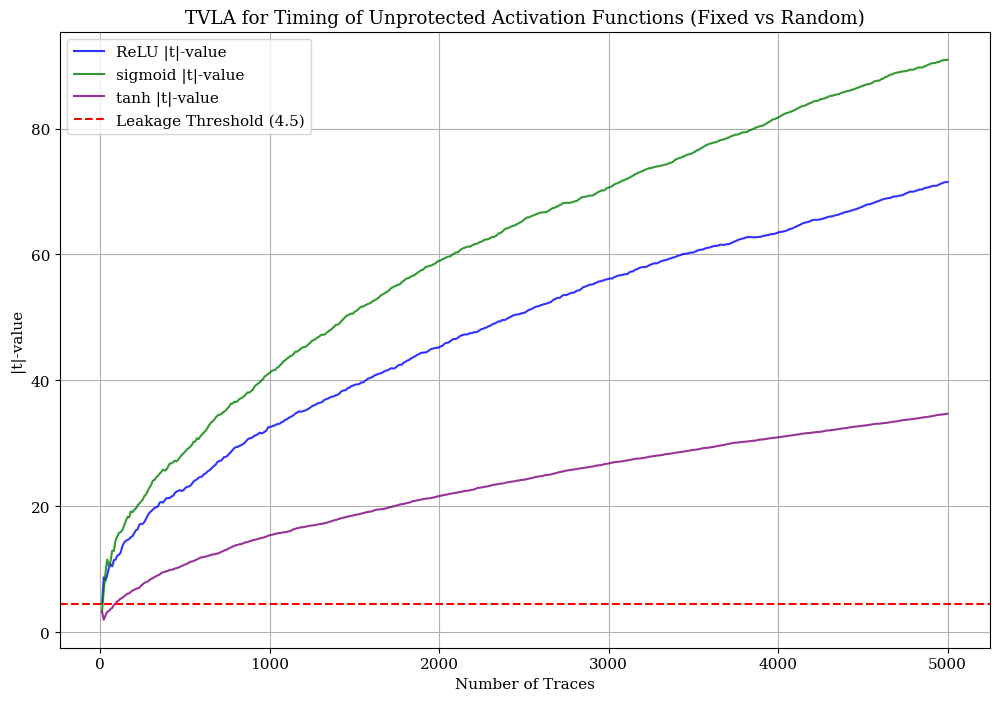

In [6]:
"""
Test Vector Leakage Assessment (TVLA) Script

This script performs a formal statistical evaluation of timing leaks using the 
non-specific "Fixed vs. Random" Welch's t-test. TVLA is the industry standard 
for formally proving the presence of side-channel vulnerabilities.

Methodology:
1. We collect one set of execution times for a single, constant (FIXED) input.
2. We collect a second set of execution times for uniformly RANDOM inputs.
3. If the device's execution time is independent of the input data (secure), the 
   statistical distributions (mean/variance) of the two sets should be identical.
4. We compute Welch's t-test between the two sets. A resulting t-statistic with 
   an absolute value > 4.5 indicates with >99.999% confidence that the two sets 
   are statistically distinguishable, proving a data-dependent timing leak exists.
"""

import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})

# Total number of traces to collect per set (5,000 fixed + 5,000 random = 10k total per function)
N = 5000

def run_tvla_test(activation_name, choice_val):
    """
    Executes the Fixed vs. Random trace collection and calculates the evolving t-statistic.
    
    Args:
        activation_name (str): The name of the function (e.g., "ReLU") for logging.
        choice_val (int): The command byte indicating which function the target should run.
        
    Returns:
        tuple: (list of trace counts (x-axis), list of absolute t-values (y-axis))
    """
    
    # --- 1. Data Generation ---
    # Generate one single random float between -2 and 2. 
    # This value will be sent N times to form the FIXED distribution.
    fixed_input = np.random.uniform(-2, 2)
    
    # Generate an array of N different random floats. 
    # These will be sent sequentially to form the RANDOM distribution.
    random_inputs = np.random.uniform(-2, 2, N)

    # Arrays to store the raw clock cycle counts for each set
    fixed_times = []
    random_times = []

    # --- 2. Fixed Trace Collection ---
    print(f"Collecting {N} FIXED traces for {activation_name} (Input: {fixed_input:.4f})...")
    for i in tqdm(range(N), desc=f"{activation_name} FIXED"):
        # Pack the command byte and the same fixed float into a byte array
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', fixed_input))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        # Read the raw ADC trigger count (execution time in clock cycles)
        fixed_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    # --- 3. Random Trace Collection ---
    print(f"Collecting {N} RANDOM traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} RANDOM"):
        # Pack the command byte and the next unique random float into a byte array
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', random_inputs[i]))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        # Read the raw ADC trigger count
        random_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    # --- 4. Statistical Analysis (TVLA) ---
    print(f"Calculating TVLA evolution for {activation_name}...")

    # We want to see how quickly the t-test detects the leak as we add more traces.
    t_values = []
    
    # Step by 10 to speed up calculation (testing at 10, 20, 30... N traces)
    traces_axis = range(10, N + 1, 10) 

    for i in traces_axis:
        # Welch's t-test compares the means of two populations.
        # equal_var=False is CRITICAL for TVLA: We cannot assume the variance of 
        # the fixed data (which only varies due to system noise) is equal to the 
        # variance of the random data (which varies due to noise AND data processing).
        t_stat, _ = ttest_ind(fixed_times[:i], random_times[:i], equal_var=False)
        
        # The TVLA standard focuses on the absolute t-value (|t|).
        # We append |t| to our list to plot its growth over time.
        t_values.append(abs(t_stat)) 
        
    return traces_axis, t_values


# --- Run Evaluation ---
# Collect data and calculate the evolving t-values for all three unprotected functions
traces_axis, relu_t = run_tvla_test("ReLU", 0)
_, sig_t = run_tvla_test("sigmoid", 1)
_, tanh_t = run_tvla_test("tanh", 2)


# --- Plotting Results ---

plt.figure(figsize=(12, 8))

# Plot the evolution of the t-statistic for each function.
# A steep curve indicates a severe, easily exploitable leakage.
plt.plot(traces_axis, relu_t, color='blue', label='ReLU |t|-value', alpha=0.8)
plt.plot(traces_axis, sig_t, color='green', label='sigmoid |t|-value', alpha=0.8)
plt.plot(traces_axis, tanh_t, color='purple', label='tanh |t|-value', alpha=0.8)

# The classical TVLA Threshold (|t| = 4.5).
# In statistics, |t| > 4.5 corresponds to a p-value of < 0.00001.
# If a line crosses this threshold, we formally declare a "fail" (the device leaks).
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Timing of Unprotected Activation Functions (Fixed vs Random)")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig(f"TVLA for Timing of Unprotected Activation Functions (Fixed vs Random).pdf", bbox_inches='tight')
plt.show()


make: Entering directory '/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/8-bit/firmware/timing_attack'
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
.
Welcome to another exciting ChipWhisperer target build!!
avr-gcc (GCC) 14.3.0
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CWLITEXMEGA 
.
Compiling:
-en     timing_attack.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/XMEGA_AES_driver.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/uart.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/usart_driver.c ...
-e Done!
.
Compiling:
-en     .././hal//xmega/xmega_hal.c ...
-e Done!
.
LINKING:
-en     timing_attack-CWLITEXMEGA.elf ...
Memory region         Used Size  Region Size  %age Used
  

ReLU capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for ReLU! Plotting results...


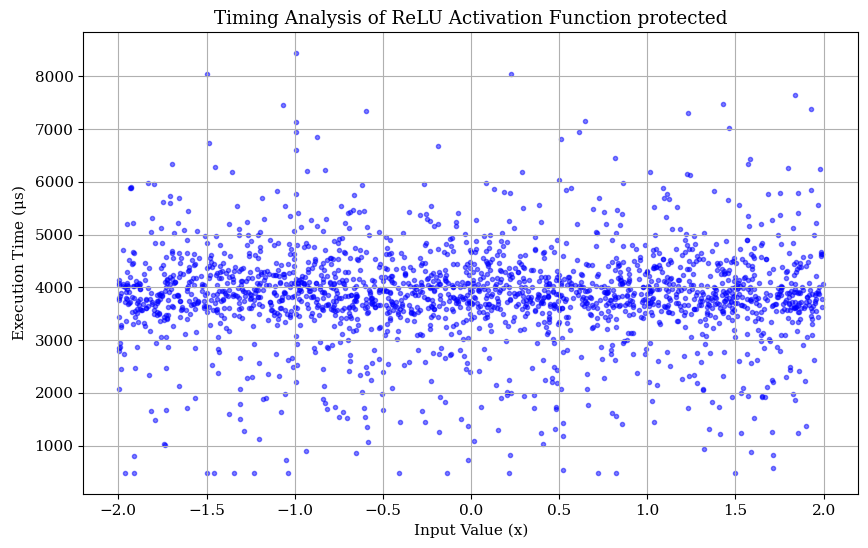

Capturing sigmoid protected...


sigmoid capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for sigmoid! Plotting results...


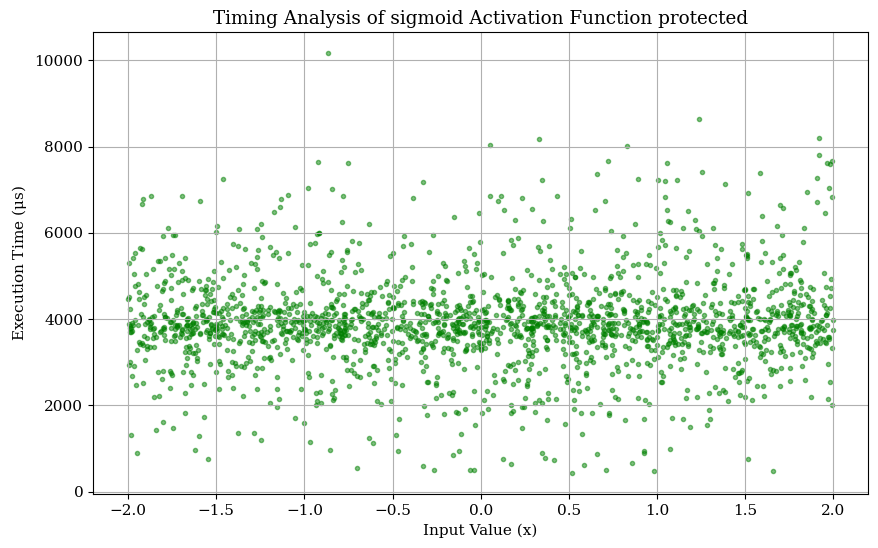

Capturing tanh protected...


tanh capture:   0%|          | 0/2000 [00:00<?, ?it/s]

Capture complete for tanh! Plotting results...


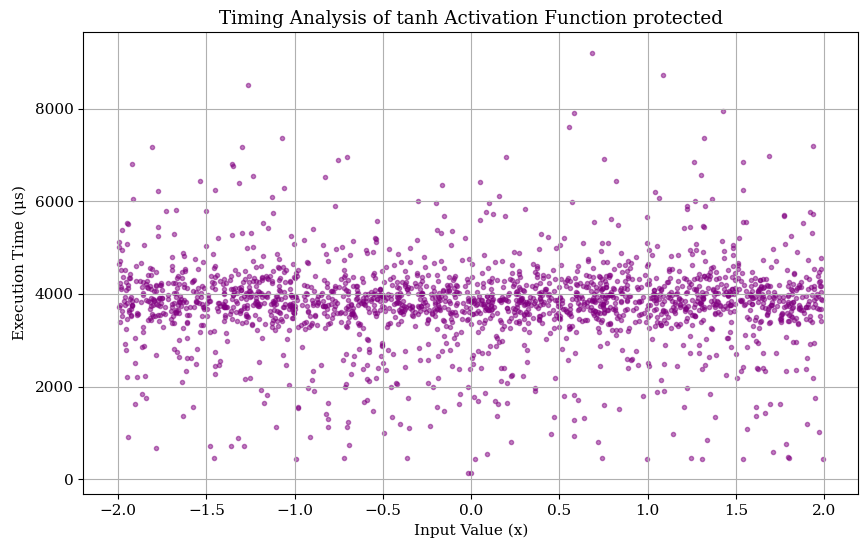

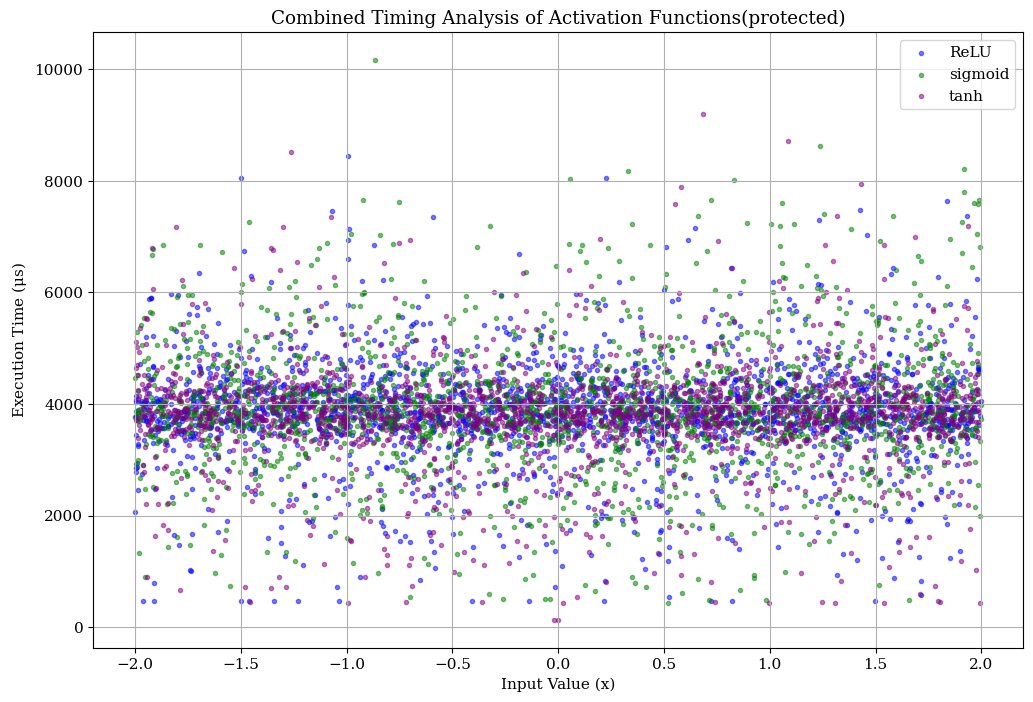

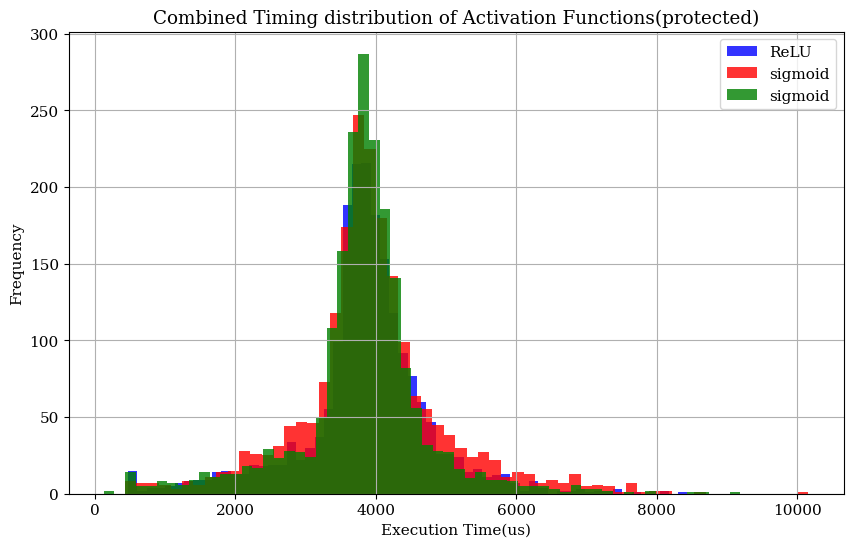

In [6]:
"""

Duplicate to run on protected implementation : uncommented the desyncronization
Timing Attack Analysis Script for 8-bit AVR

This script utilizes the ChipWhisperer toolchain to perform a side-channel 
timing analysis on unprotected neural network activation functions (ReLU, Sigmoid, Tanh).
It compiles the firmware, flashes it to the target board, feeds it random floating-point inputs, 
and measures the exact execution time (in clock cycles/microseconds) using the oscilloscope's trigger. 

The resulting timing leaks are plotted 
and analyzed using K-Means clustering to determine the parameters needed for a 
randomized delay countermeasure.


"""

import struct
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.vq import kmeans
from tqdm.notebook import tqdm
import os

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})

# --- Target Setup & Firmware Compilation ---

PLATFORM = 'CWLITEXMEGA'
FW_PATH = "../firmware/timing_attack/"
!make -C "{FW_PATH}" PLATFORM={PLATFORM} CRYPTO_TARGET=NONE
hex_path = os.path.join(FW_PATH, f"timing_attack-{PLATFORM}.hex")
cw.program_target(scope, cw.programmers.XMEGAProgrammer, hex_path)

def capture_and_plot(activation_name, choice_val=None, num_traces=2000, suffix="", color="red"):

    # Generate 2000 random inputs
    inputs = np.random.uniform(-2, 2, num_traces)

    # Store execution times in microseconds
    execution_times_us = [] 

    print(f"Capturing {activation_name}{suffix}...")

    # used to convert cycles to time
    adc_freq = scope.clock.adc_freq 

    for x in tqdm(inputs, desc=f"{activation_name} capture"):

        # pack our chosen activation function and input value
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', x))
        
        scope.arm()

        # send the input to the target, this starts the execution
        target.simpleserial_write('p', pt)
        
        # wait for the execution to finish
        ret = scope.capture()
        if ret:
            print("Timeout error! The trigger never fired or finished.")
            break
            
        # Get the number of cycles from the ADC
        cycles = scope.adc.trig_count

        # Convert cycles to actual time in microseconds (1e6 microseconds in a second)
        time_us = (cycles / adc_freq) * 1e6 

        # append the execution time to the list
        execution_times_us.append(time_us)
        
        # read the output from the target(acknowledge)
        target.simpleserial_read('r', 4)

    print(f"Capture complete for {activation_name}! Plotting results...")

    plt.figure(figsize=(10, 6))
    plt.scatter(inputs, execution_times_us, marker='.', color=color, alpha=0.5)
    plt.title(f"Timing Analysis of {activation_name} Activation Function{suffix}")
    plt.xlabel("Input Value (x)")
    plt.ylabel(r"Execution Time ($\mu s$)")
    plt.grid(True)
    plt.savefig(f"{activation_name}-{suffix}.pdf", bbox_inches='tight')
    plt.show()
    
    return inputs, execution_times_us


# Run for all activation functions and save results
relu_in, relu_out = capture_and_plot("ReLU", 0, suffix=" protected", color="blue")
sig_in, sig_out = capture_and_plot("sigmoid", 1, suffix=" protected", color="green")
tanh_in, tanh_out = capture_and_plot("tanh", 2, suffix=" protected", color="purple")



# Combined Overlay Plot
plt.figure(figsize=(12, 8))

# Plot all data
plt.scatter(relu_in, relu_out, marker='.', color="blue", alpha=0.5, label="ReLU")
plt.scatter(sig_in, sig_out, marker='.', color="green", alpha=0.5, label="sigmoid")
plt.scatter(tanh_in, tanh_out, marker='.', color="purple", alpha=0.5, label="tanh")

plt.title("Combined Timing Analysis of Activation Functions(protected)")
plt.xlabel("Input Value (x)")
plt.ylabel(r"Execution Time ($\mu s$)")
plt.legend()
plt.grid(True)
plt.savefig('combined_timing(protected).pdf', bbox_inches='tight')
plt.show()

# Overlay Histogram Visualization
plt.figure(figsize=(10,6))
plt.hist( relu_out,bins=60, color='blue',alpha=0.8, label='ReLU')
plt.hist(sig_out, bins=60, color='red',alpha=0.8,  label="sigmoid")
plt.hist(tanh_out, bins=60, color='green',alpha=0.8,  label="sigmoid")
plt.title("Combined Timing distribution of Activation Functions(protected)")
plt.xlabel('Execution Time(us)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.savefig('histogram(protected).pdf', bbox_inches='tight')
plt.show()

ReLU FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

ReLU RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for ReLU...


sigmoid FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for sigmoid...


tanh FIXED:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh RANDOM:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating TVLA evolution for tanh...


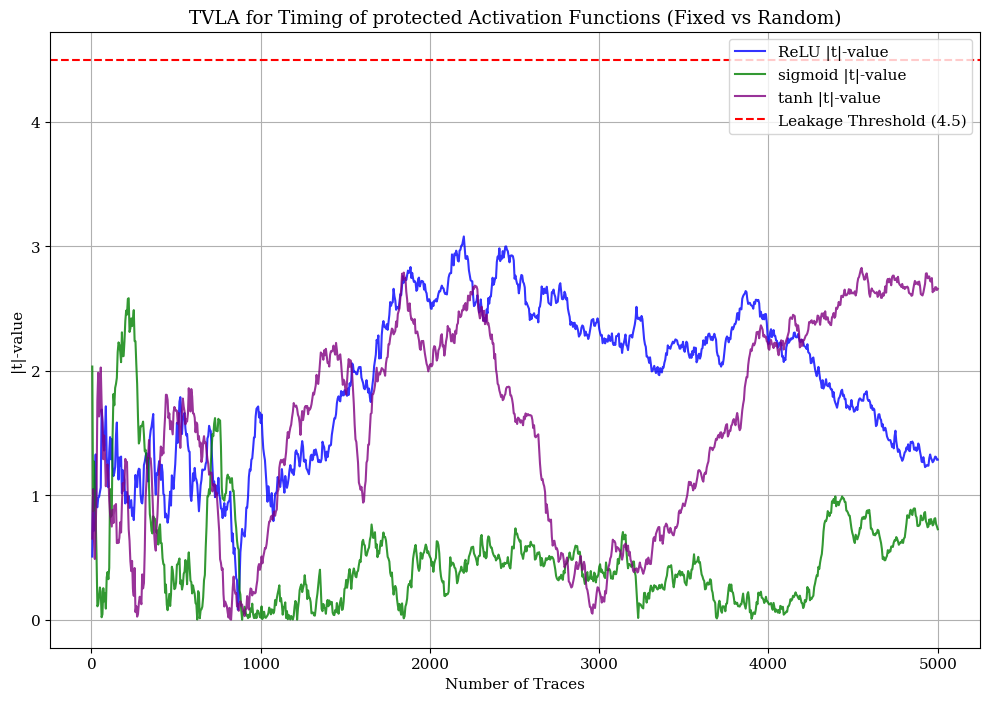

In [3]:
import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})


N = 5000

def run_tvla_test(activation_name, choice_val):
    # Chosen randomly at the beginning but fixed for the rest of experiment
    fixed_input = np.random.uniform(-2, 2)
    # Each is chosen randomly and different from each inference execution
    random_inputs = np.random.uniform(-2, 2, N)

    fixed_times = []
    random_times = []

    print(f"Collecting {N} FIXED traces for {activation_name} (Input: {fixed_input:.4f})...")
    for i in tqdm(range(N), desc=f"{activation_name} FIXED"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', fixed_input))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        fixed_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    print(f"Collecting {N} RANDOM traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} RANDOM"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', random_inputs[i]))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        random_times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)

    print(f"Calculating TVLA evolution for {activation_name}...")

    # Calculate the evolving t-statistic over the number of traces
    t_values = []
    traces_axis = range(5, N + 1, 5) # Calculate every 10 traces for speed

    for i in traces_axis:
        # equal_var=False applies Welch's t-test 
        t_stat, _ = ttest_ind(fixed_times[:i], random_times[:i], equal_var=False)
        t_values.append(abs(t_stat)) # The paper specifically plots |t|-values
        
    return traces_axis, t_values

# Run TVLA for all three functions
traces_axis, relu_t = run_tvla_test("ReLU", 0)
_, sig_t = run_tvla_test("sigmoid", 1)
_, tanh_t = run_tvla_test("tanh", 2)

# Evolution of |t|-value overlayed
plt.figure(figsize=(12, 8))

plt.plot(traces_axis, relu_t, color='blue', label='ReLU |t|-value', alpha=0.8)
plt.plot(traces_axis, sig_t, color='green', label='sigmoid |t|-value', alpha=0.8)
plt.plot(traces_axis, tanh_t, color='purple', label='tanh |t|-value', alpha=0.8)

# Add the classical ±4.5 threshold line (since it's absolute |t|, just 4.5)
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Timing of protected Activation Functions (Fixed vs Random)")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig(f"TVLA for Timing of protected Activation Functions (Fixed vs Random).pdf", bbox_inches='tight')
plt.show()


In [2]:
import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from tqdm.notebook import tqdm

N = 5000

# Generate ONE set of random inputs to use for all three functions
shared_random_inputs = np.random.uniform(-2, 2, N)

def collect_traces(activation_name, choice_val):
    times = []
    print(f"Collecting {N} traces for {activation_name}...")
    for i in tqdm(range(N), desc=f"{activation_name} Traces"):
        pt = bytearray([choice_val]) + bytearray(struct.pack('f', shared_random_inputs[i]))
        
        scope.arm()
        target.simpleserial_write('p', pt)
        scope.capture()
        
        times.append(scope.adc.trig_count)
        target.simpleserial_read('r', 4)
        
    return times

# Collect data for all three functions using the SAME input data array
relu_times = collect_traces("ReLU", 0)
sig_times = collect_traces("sigmoid", 1)
tanh_times = collect_traces("tanh", 2)

print("Calculating cross function TVLA evolution...")

# Calculate the evolving t-statistics over the number of traces
traces_axis = range(10, N + 1, 10) 

t_relu_vs_sig = []
t_sig_vs_tanh = []
t_relu_vs_tanh = []

for i in traces_axis:
    # 1. Compare ReLU vs Sigmoid
    t_stat1, _ = ttest_ind(relu_times[:i], sig_times[:i], equal_var=False)
    t_relu_vs_sig.append(abs(t_stat1))
    
    # 2. Compare Sigmoid vs Tanh
    t_stat2, _ = ttest_ind(sig_times[:i], tanh_times[:i], equal_var=False)
    t_sig_vs_tanh.append(abs(t_stat2))
    
    # 3. Compare ReLU vs Tanh
    t_stat3, _ = ttest_ind(relu_times[:i], tanh_times[:i], equal_var=False)
    t_relu_vs_tanh.append(abs(t_stat3))


ReLU Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

sigmoid Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

tanh Traces:   0%|          | 0/5000 [00:00<?, ?it/s]

Calculating cross function TVLA evolution...


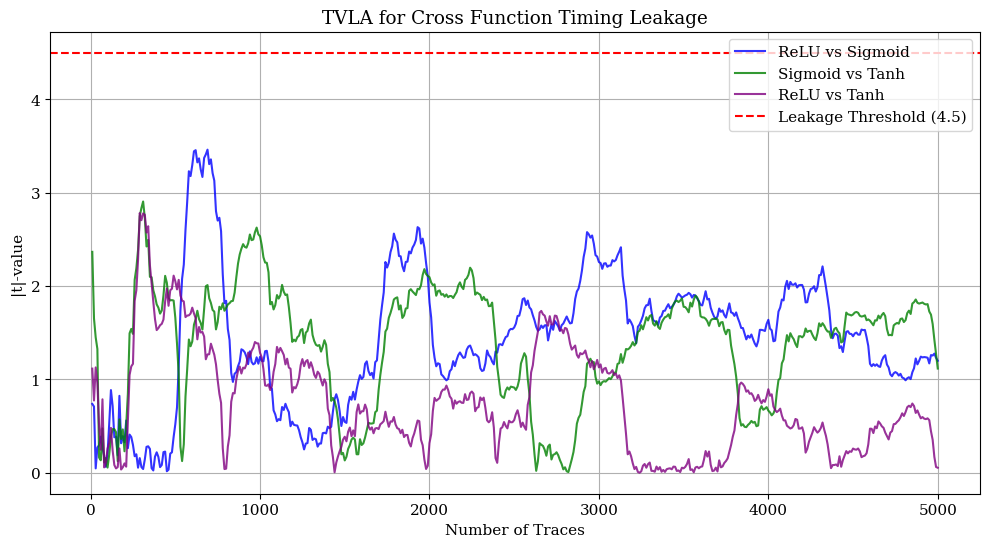

In [3]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})
# Plotting the Inter-Function Leakage
plt.figure(figsize=(12, 6))

plt.plot(traces_axis, t_relu_vs_sig, color='blue', label='ReLU vs Sigmoid', alpha=0.8)
plt.plot(traces_axis, t_sig_vs_tanh, color='green', label='Sigmoid vs Tanh', alpha=0.8)
plt.plot(traces_axis, t_relu_vs_tanh, color='purple', label='ReLU vs Tanh', alpha=0.8)

# Threshold line
plt.axhline(4.5, color='red', linestyle='dashed', label='Leakage Threshold (4.5)')

plt.title("TVLA for Cross Function Timing Leakage")
plt.xlabel("Number of Traces")
plt.ylabel("|t|-value")
plt.legend()
plt.grid(True)
plt.savefig('TVLA for Cross Function Timing Leakage.pdf', bbox_inches='tight')
plt.show()



Calculating cross function AD-test evolution...


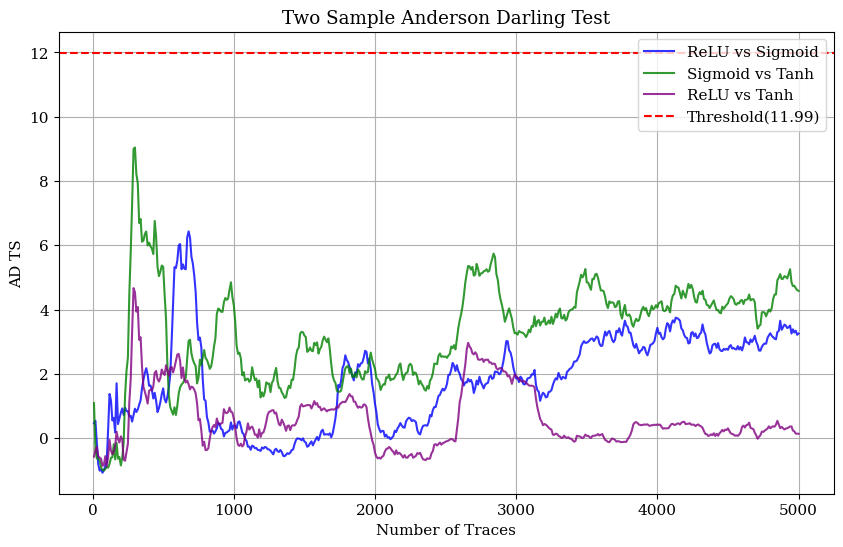

In [4]:
import warnings
from scipy.stats import anderson_ksamp
import matplotlib.pyplot as plt


print("Calculating cross function AD-test evolution...")

ad_relu_vs_sig = []
ad_sig_vs_tanh = []
ad_relu_vs_tanh = []

# The anderson_ksamp function often throws warnings when the estimated p-value
# is extremely small (< 0.001) or very large (> 0.25). 
# We suppress these warnings here to prevent flooding your output during the loop.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    for i in traces_axis:
        # anderson_ksamp takes a list of the sample arrays you want to compare.
        # It returns an object containing the 'statistic', 'critical_values', and 'pvalue'.
        # We extract .statistic as our leakage metric.
        
        # 1. Compare ReLU vs Sigmoid
        res1 = anderson_ksamp([relu_times[:i], sig_times[:i]])
        ad_relu_vs_sig.append(res1.statistic)
        
        # 2. Compare Sigmoid vs Tanh
        res2 = anderson_ksamp([sig_times[:i], tanh_times[:i]])
        ad_sig_vs_tanh.append(res2.statistic)
        
        # 3. Compare ReLU vs Tanh
        res3 = anderson_ksamp([relu_times[:i], tanh_times[:i]])
        ad_relu_vs_tanh.append(res3.statistic)

# --- Plotting the Results ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Liberation Serif", "Times New Roman"],
    "mathtext.fontset": "cm",      # Use Computer Modern for all math symbols!
    "mathtext.default": "regular", # Keep text and variables consistent
    "figure.figsize": (8, 5),
    "font.size": 11,
})

plt.figure(figsize=(10, 6))

plt.plot(traces_axis, ad_relu_vs_sig, color="blue", label='ReLU vs Sigmoid', alpha=0.8)
plt.plot(traces_axis, ad_sig_vs_tanh, color="green", label='Sigmoid vs Tanh', alpha=0.8)
plt.plot(traces_axis, ad_relu_vs_tanh, color="purple", label='ReLU vs Tanh', alpha=0.8)

# For a 2-sample AD-test, the critical value for a 0.001 (0.1%) significance level 
# is typically ~6.546 based on Scipy's tabulated values.
# If a statistic goes over this line, we confidently reject the null hypothesis 
# that the distributions are identical (indicating a timing leakage).
plt.axhline(y=11.99, color='red', linestyle='--', label='Threshold(11.99)')

plt.title('Two Sample Anderson Darling Test')
plt.xlabel('Number of Traces')
plt.ylabel('AD TS')
plt.legend()
plt.grid(True)
plt.savefig('Two Sample Anderson Darling Test.pdf', bbox_inches='tight')
plt.show()


